# Challenge 2 – Classification into screws and nuts

**Task.** Classify every segmented part as screw or nut, and report the number of screws and of nuts in each image. Long fasteners with a head (screws, bolts, nails) are _screws_.

**Requirements:**
- Extract as many descriptors as you find useful (shape, topology, moments. . . ) and study them: distribution per class, discriminative power, invariance to rotation and scale, redundancy. Justify the subset you keep.
- Use at least N classification methodologies of different nature (e.g. rules / decision trees, k-NN, LDA/QDA, logistic regression, SVM, ensembles. . . ) and justify their use and their hyper-parameters.
- Discuss how each classifier behaves when the segmentation is imperfect (false positives, lost holes, merged parts).

## 1. Feature extraction

First of all, we need to decide what features we want to extract from the segmented parts. The following list contains some possible descriptors that can be used for classification:


In the braclets, invariance by T:translation, R:rotation, S:scale is indicated.
List of possible descriptors:
- Shape
    - Area/size {TR}
        - Not really discriminative, as there are small screws and big nuts.
    - Perimeter {TR}
        - Not really discriminative, as there are small screws and big nuts.
    - Circularity {TRS}
        - Discriminative, as screws are elongated and nuts are more circular.
    - Eccentricity {TRS}
        - Discriminative, as screws are elongated and nuts are more circular.
    - Solidity (concavity) {TRS}
        - Very discriminative, as screws have concave parts (the area from the head to the peak) and nuts are convex.
    - Simmetries {TRS}
        - Discriminative:
            - Screws have none to a single axis of symmetry (the axis that goes from the head to the peak, if we don't consider the thread).
            - Nuts have multiple axes of symmetry.
    - Vertex, edge, curvature {TR}
        - Discriminative, but in two and opposite cases:
            -  If we consider the thread, screws have many edges and vertices, while nuts have few.
            - If we don't consider the thread, screws have few edges and vertices, while nuts have many.
            - The decision depends on how much the post-processing of the first challenge eroded the threads.
    - Circle structure {TRS}
        - Discriminative, as the Hough transform can detect the circular holes in the nuts.
- Topological Descriptors
    - Euler number {TRS}
        - Very discriminative, as screws have a single connected component, while nuts have two (the outer and the inner). Note: the mask of the screws must be completely filled.
- Moments
    - Hu moments {TRS}
        - Discriminative, as they are invariant to rotation and scale, and can be used to distinguish between screws and nuts.
        - Still, they might be an overkill, as the other descriptors are already discriminative enough. Considering it as a last resort.

In [15]:
# Environment setup
import cv2
import numpy as np
import pandas as pd
from skimage import measure
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import GroupKFold
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis


# Define project paths
ANNOTATIONS_DIR = Path("annotations")

OUTPUT_DIR = Path("outputs")

C1_OUTPUT_DIR = OUTPUT_DIR / "challenge_1_results"
C2_OUTPUT_DIR = OUTPUT_DIR / "challenge_2_results"
C2_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IOU_MATCHING_THRESHOLD = 0.5  # Threshold for matching predicted masks with ground truth annotations using IoU
ECCENTRICITY_THRESHOLD = 0.515  # Threshold for classifying parts based on eccentricity

### 1.2. Hough Transform for hole/circle detection and simmetry detection {DEPRECATED. DID NOT WORK, NOT NEEDED}

In [16]:
def check_circle_structure(crop_mask: np.ndarray) -> bool:
    """
    Check if the segmented part has a circular structure (hole) using Hough Transform.

    Args:
        crop_mask (np.ndarray): 16-bit mask of the segmented part.

    Returns:
        bool: True if a circular structure is detected, False otherwise.
    """

    crop_uint8 = (crop_mask * 255).astype(np.uint8)

    circles = cv2.HoughCircles(
        crop_uint8,
        cv2.HOUGH_GRADIENT,
        dp=1,
        minDist=20,
        param1=50,
        param2=30, # Sensibility threshold for imperfect circle detection
        minRadius=5,
        maxRadius=50
    )

    return circles is not None

def check_symmetry(crop_mask: np.ndarray) -> int:
    """
    Check the number of axes of symmetry in the segmented part.

    Args:
        crop_mask (np.ndarray): 16-bit mask of the segmented part.

    Returns:
        int: Number of axes of symmetry detected.
    """
    # Placeholder for symmetry detection logic
    # This can be implemented using image processing techniques
    # For now, we return a dummy value
    return 0

### 1.3 Feature extraction function
This code:
- extracts the features from the mask components and matches them to the ground truth annotations using IoU;
- extract shape and topological descriptors from the masks using `skimage.measure.regionprops` and custom functions for circularity and symmetry;
- returns a DataFrame with the extracted features and the matched ground truth type (screw/nut)


In [33]:
import numpy as np
import pandas as pd
from pathlib import Path
import cv2
from skimage import measure

def extract_part_features(mask_16bit: np.ndarray, image_stem: str) -> pd.DataFrame:
    # 1. Extract shape and topological descriptors from the mask using skimage.measure.regionprops
    regions = measure.regionprops(mask_16bit)

    if not regions:
        print(f"No regions found in mask for image {image_stem}.")
        return pd.DataFrame()

    properties = ['label', 'area', 'perimeter', 'eccentricity', 'solidity', 'euler_number']
    features_df = pd.DataFrame(measure.regionprops_table(mask_16bit, properties=properties))

    eps = 1e-6
    features_df['circularity'] = (4 * np.pi * features_df['area']) / (features_df['perimeter'] ** 2 + eps)

    is_circle_list = []
    symmetry_list = []

    for region in regions:
        crop_bool = region.image
        is_circle_list.append(check_circle_structure(crop_bool))
        symmetry_list.append(check_symmetry(crop_bool))

    features_df['is_circle'] = is_circle_list
    features_df['symmetry'] = symmetry_list

    # 2. Matching the extracted features with the ground truth annotations using IoU
    gt_mask_path = ANNOTATIONS_DIR / f"{image_stem}_labels.png"
    annotation_csv_path = ANNOTATIONS_DIR / "parts.csv"

    if gt_mask_path.exists() and annotation_csv_path.exists():
        gt_mask_16bit = cv2.imread(str(gt_mask_path), cv2.IMREAD_UNCHANGED)
        annotations_df = pd.read_csv(annotation_csv_path)

        # Cleaning the names to match it
        annotations_df['image_clean'] = annotations_df['image'].apply(
            lambda x: Path(x).stem.replace(r"(_labels?|_label_image|\.png|\.jpg|\.tiff?)$", "")
        )
        df_image_annotations = annotations_df[annotations_df['image_clean'] == image_stem]

        gt_regions = measure.regionprops(gt_mask_16bit)

        matched_types = []
        matched_gt_ids = []

        # Comparing IoU
        for region in regions:
            pred_binary = (mask_16bit == region.label)

            best_iou = 0.0
            best_gt_label = None

            for gt_region in gt_regions:
                gt_binary = (gt_mask_16bit == gt_region.label)

                # IoU calculation
                intersection = np.logical_and(pred_binary, gt_binary).sum()
                union = np.logical_or(pred_binary, gt_binary).sum()

                iou = intersection / union if union > 0 else 0.0

                if iou > best_iou:
                    best_iou = iou
                    best_gt_label = gt_region.label

            # IoU >= threshold
            if best_iou >= IOU_MATCHING_THRESHOLD and best_gt_label is not None:
                gt_info = df_image_annotations[df_image_annotations['part_id'] == best_gt_label]
                if not gt_info.empty:
                    matched_types.append(gt_info.iloc[0]['type'])
                    matched_gt_ids.append(best_gt_label)
                else:
                    matched_types.append(np.nan)
                    matched_gt_ids.append(np.nan)
            else:
                # False positive
                matched_types.append(np.nan)
                matched_gt_ids.append(np.nan)

        features_df['type'] = matched_types
        features_df['gt_part_id'] = matched_gt_ids
    else:
        if not gt_mask_path.exists():
            print(f"Warning: Maschera GT non trovata: {gt_mask_path.name}")
        features_df['type'] = np.nan
        features_df['gt_part_id'] = np.nan

    features_df.insert(0, 'image_stem', image_stem)
    return features_df

1.4 Feature extraction for all images

In [34]:
# First, it is needed to match the labels in the mask with the labels in the annotations, when available.

# No need to process the images of different types as the features are extracted from the masks that are generated as PNG files in the challenge 1.
mask_files = sorted(list(C1_OUTPUT_DIR.glob("*.png")))

print(f"Found {len(mask_files)} mask files for feature extraction.")

all_features_list = []

for mask_path in mask_files:
    mask_array = cv2.imread(str(mask_path), cv2.IMREAD_UNCHANGED)

    if mask_array is None:
        print(f"Warning: Impossibile leggere il file {mask_path.name}")
        continue

    image_stem = mask_path.stem.replace("_label_image", "")

    df_single = extract_part_features(mask_array, image_stem=image_stem)

    if not df_single.empty:
        all_features_list.append(df_single)
        print(f" Processata: {mask_path.name} -> Estratti {len(df_single)} componenti.")

# Concatenate all features into a single DataFrame
if all_features_list:
    df_dataset = pd.concat(all_features_list, ignore_index=True)

    csv_output_path = C2_OUTPUT_DIR / "extracted_features.csv"
    df_dataset.to_csv(csv_output_path, index=False)

    print("\n Estrazione completata con successo!")
    print(f"Dataset salvato in: {csv_output_path}")
    print(f"Dimensioni finali dataset: {df_dataset.shape} (righe/componenti x colonne/feature)")

    display(df_dataset)
else:
    print("Nessuna feature estratta. Controlla le maschere e il codice di estrazione.")



Found 10 mask files for feature extraction.
 Processata: screws_026_label_image.png -> Estratti 8 componenti.
 Processata: screws_027_label_image.png -> Estratti 8 componenti.
 Processata: screws_028_label_image.png -> Estratti 8 componenti.
 Processata: screws_029_label_image.png -> Estratti 8 componenti.
 Processata: screws_040_label_image.png -> Estratti 10 componenti.
 Processata: screws_041_label_image.png -> Estratti 9 componenti.
 Processata: screws_042_label_image.png -> Estratti 10 componenti.
 Processata: screws_061_label_image.png -> Estratti 8 componenti.
 Processata: screws_063_label_image.png -> Estratti 8 componenti.
 Processata: screws_119_label_image.png -> Estratti 9 componenti.

 Estrazione completata con successo!
Dataset salvato in: outputs/challenge2/extracted_features.csv
Dimensioni finali dataset: (86, 12) (righe/componenti x colonne/feature)


,image_stem,label,area,perimeter,eccentricity,solidity,euler_number,circularity,is_circle,symmetry,type,gt_part_id
0,screws_026,1,13341.0,691.126984,0.953661,0.661362,1,0.350980,False,0,screw,3.0
1,screws_026,2,11421.0,803.820418,0.986028,0.619360,1,0.222124,False,0,screw,4.0
2,screws_026,3,11333.0,771.653896,0.986214,0.638119,1,0.239172,False,0,screw,5.0
3,screws_026,4,2667.0,279.078210,0.174912,0.863386,0,0.430310,False,0,nut,8.0
4,screws_026,5,2713.0,278.249783,0.212081,0.871227,0,0.440342,False,0,nut,7.0
...,...,...,...,...,...,...,...,...,...,...,...,...
81,screws_119,5,4866.0,416.717821,0.162916,0.804963,0,0.352126,False,0,nut,4.0
82,screws_119,6,2771.0,276.936075,0.138595,0.878846,0,0.454033,False,0,nut,5.0
83,screws_119,7,24976.0,1051.187950,0.092737,0.741084,0,0.284035,False,0,nut,3.0
84,screws_119,8,11300.0,808.305699,0.987036,0.614264,1,0.217339,False,0,screw,2.0


### 1.5 Feature analysis

Scatterplots that might be interesting:
- Eccentricity vs. Area
- Eccentricity vs. Perimeter
- Area vs. Perimeter
- Solidity vs Euler number
- Eccentricity vs Circularity



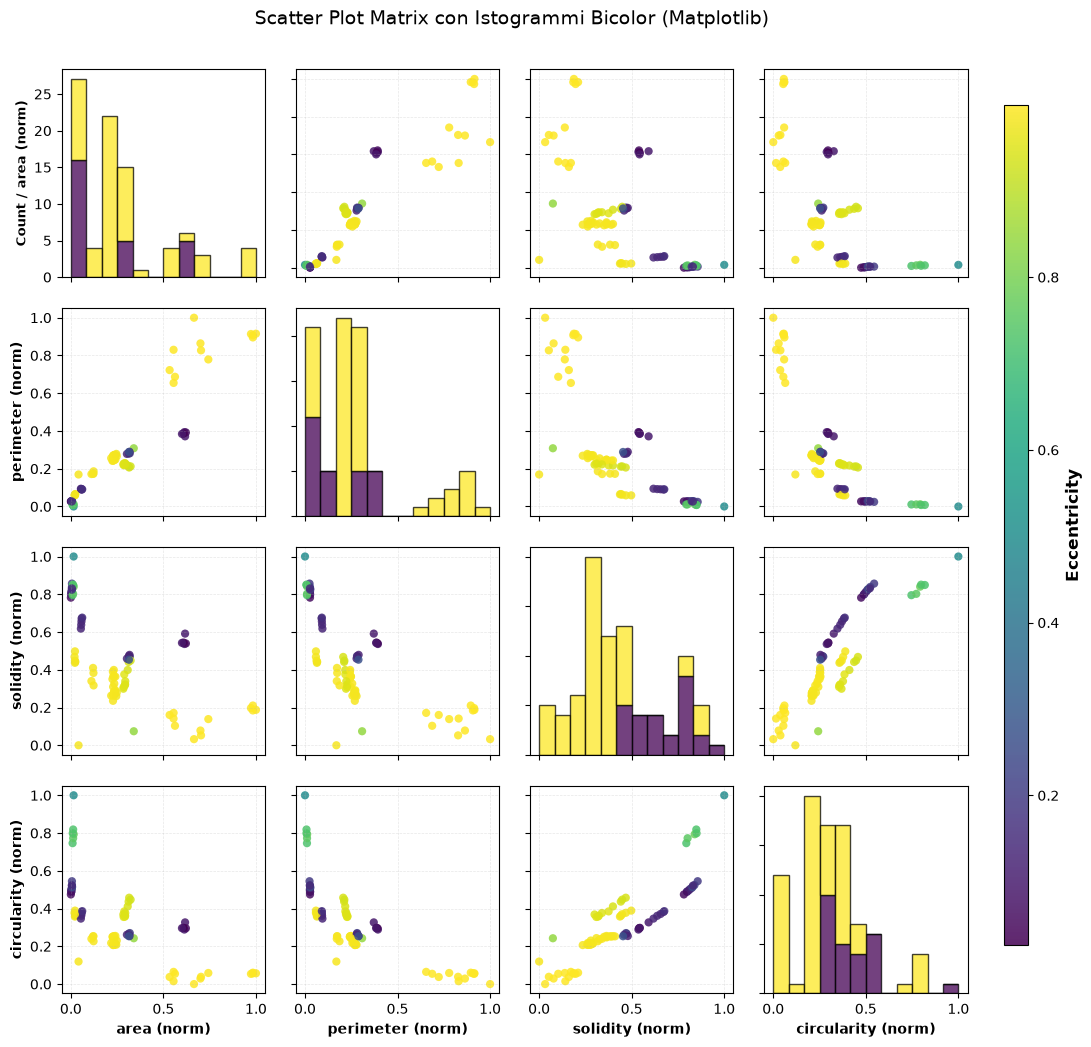

In [35]:
# 1. Normalisation of the features for better visualisation and compatibility with model training.
df_plot = df_dataset.copy()
features = ['area', 'perimeter', 'solidity', 'circularity']

for col in features:
    min_val = df_plot[col].min()
    max_val = df_plot[col].max()
    df_plot[col] = (df_plot[col] - min_val) / (max_val - min_val)

n_feats = len(features)
fig, axes = plt.subplots(n_feats, n_feats, figsize=(12, 12))
ecc = df_plot['eccentricity']

is_nut = df_plot['eccentricity'] < ECCENTRICITY_THRESHOLD

sc = None


for i in range(n_feats):
    feature_y = features[i]
    for j in range(n_feats):
        feature_x = features[j]
        ax = axes[i, j]

        if i == j:
            ax.hist(
                [df_plot.loc[is_nut, feature_x], df_plot.loc[~is_nut, feature_x]],
                bins=12,
                stacked=True,
                color=['#440154', '#fde725'], # Purple (Nut/low) e Others (Yellow-Green) (Screw/high)
                edgecolor='black',
                alpha=0.75
            )
            ax.set_xlim(-0.05, 1.05)
        else:
            sc = ax.scatter(
                df_plot[feature_x],
                df_plot[feature_y],
                c=ecc,
                cmap='viridis',
                alpha=0.85,
                edgecolors='none',
                s=35
            )
            ax.grid(True, linestyle='--', alpha=0.3)
            ax.set_ylim(-0.05, 1.05)
            ax.set_xlim(-0.05, 1.05)

        lbl_x = f"{feature_x} (norm)"
        lbl_y = f"{feature_y} (norm)"

        if i == n_feats - 1:
            ax.set_xlabel(lbl_x, fontsize=10, fontweight='bold')
        else:
            ax.set_xticklabels([])

        if j == 0:
            if i == 0:
                ax.set_ylabel(f"Count / {lbl_y}", fontsize=9, fontweight='bold')
            else:
                ax.set_ylabel(lbl_y, fontsize=10, fontweight='bold')
        else:
            ax.set_yticklabels([])

fig.subplots_adjust(right=0.88, hspace=0.15, wspace=0.15)
cbar_ax = fig.add_axes([0.91, 0.15, 0.02, 0.7])

if sc is not None:
    cbar = fig.colorbar(sc, cax=cbar_ax)
    cbar.set_label('Eccentricity', fontsize=12, fontweight='bold')

plt.suptitle("Scatter Plot Matrix with Coloured Histograms", y=0.93, fontsize=14)
plt.show()

## 2. Classification
By a quick analysis of the features extracted, we can see that some of them are more discriminative than others. For example, we can see that the eccentricity is very discriminative alone, it creates two very distinct clusters, one with maximum e. of ~33% and the other with a minimum of ~69%.

1. **Rule-based classification using had crafted thresholds.** This approach was included to show the possibility of creating an (almost) completely unsupervised classification.
By the previous data analysis, we can see that the eccentricity is very discriminative alone, it creates two very distinct clusters, one with maximum e. of ~34% and the other with a minimum of ~69%. These percentages come from a previous run on annotated labelled, but the results on the derived masks are very similar.
2. **Test split.** With GroupKFold, training and test sets are created. Using GroupKFold prevents data leakage and ensures that the model is evaluated on unseen images.
3. **Trained models.** Different kinds of models are trained on these datasets with two different feature sets:
    - **Feature set A:** all the features except Eccentricity, to see if the other features can be discriminative enough.
    - **Feature set B:** only Eccentricity, as it was already seen to be very discriminative just with a simple threshold.
4. **Evaluation.** The models are evaluated using accuracy and F1-score, and the results are compared in a summary table, together with the rule-based classification.

**Expectation:** We expect that the rule-based classification will perform near 100% accuracy, as the threshold was derived from the data analysis. The other models might perform similarly or slightly worse, depending on their ability to learn from the features provided.

**Models:**
- Decision Tree Classifier
    - **Why?** {TODO: justify}
- Logistic Regression
    - **Why?** {TODO: justify}
- SVM (RBF)
    - **Why?** {TODO: justify}
- Quadratic Discriminant Analysis (QDA)
    - **Why?** {TODO: justify}

In [43]:
import pandas as pd
import numpy as np
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.metrics import accuracy_score, f1_score

# Dropping rows with NaN in 'type': either unlabeled parts or false positives.
df_clean = df_dataset.dropna(subset=['type']).copy().reset_index(drop=True)
df_clean['type'] = df_clean['type'].astype(str).str.strip().str.lower()

# Feature sets for classification
feature_set_A = ['perimeter', 'area', 'circularity', 'solidity', 'euler_number']
feature_set_B = ['eccentricity']

# Models to evaluate
models = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Logistic Regression': Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression())]),
    'SVM (RBF)': Pipeline([('scaler', StandardScaler()), ('clf', SVC(kernel='rbf'))]),
    'QDA (reg=0.1)': Pipeline([('scaler', StandardScaler()), ('clf', QuadraticDiscriminantAnalysis(reg_param=0.1))])
}

# Rule-based classification function based on eccentricity threshold
def classify_part_rule_based(eccentricity_series, threshold=0.515):
    return np.where(eccentricity_series < threshold, 'nut', 'screw')

# Evaluation function for feature sets and models
def evaluate_feature_set(df, feature_list, set_name="Feature Set", include_rule_based=True):
    X = df[feature_list].copy()

    for col in X.columns:
        if X[col].dtype == 'object' or X[col].dtype == 'bool':
            X[col] = X[col].astype(float)

    y = df['type']
    groups = df['image_stem']

    gkf = GroupKFold(n_splits=5)
    results = []

    if include_rule_based:
        rule_fold_accuracies = []
        rule_fold_f1s = []

        for fold, (train_idx, test_idx) in enumerate(gkf.split(X, y, groups=groups)):
            y_test = y.iloc[test_idx]
            ecc_test = df.iloc[test_idx]['eccentricity']

            y_pred_rule = classify_part_rule_based(ecc_test, threshold=0.515)

            rule_fold_accuracies.append(accuracy_score(y_test, y_pred_rule))
            rule_fold_f1s.append(f1_score(y_test, y_pred_rule, pos_label='screw'))

        results.append({
            'Feature Set': set_name,
            'Model': 'Rule-Based Baseline (ecc < 0.515)',
            'Mean Accuracy': np.mean(rule_fold_accuracies),
            'Std Accuracy': np.std(rule_fold_accuracies),
            'Mean F1-Score': np.mean(rule_fold_f1s)
        })

    # Evaluate supervised models
    for model_name, model in models.items():
        fold_accuracies = []
        fold_f1s = []

        for fold, (train_idx, test_idx) in enumerate(gkf.split(X, y, groups=groups)):
            X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
            y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)

            fold_accuracies.append(accuracy_score(y_test, y_pred))
            fold_f1s.append(f1_score(y_test, y_pred, pos_label='screw'))

        results.append({
            'Feature Set': set_name,
            'Model': model_name,
            'Mean Accuracy': np.mean(fold_accuracies),
            'Std Accuracy': np.std(fold_accuracies),
            'Mean F1-Score': np.mean(fold_f1s)
        })

    return pd.DataFrame(results)

# Comparing the features sets and models
df_res_A = evaluate_feature_set(df_clean, feature_set_A, set_name="All useful features", include_rule_based=False)
df_res_B = evaluate_feature_set(df_clean, feature_set_B, set_name="Only Eccentricity", include_rule_based=True)

df_comparison = pd.concat([df_res_A, df_res_B], ignore_index=True)
display(df_comparison)

,Feature Set,Model,Mean Accuracy,Std Accuracy,Mean F1-Score
0,All useful features,Decision Tree,0.976471,0.028818,0.983304
1,All useful features,Logistic Regression,0.895343,0.040151,0.922455
2,All useful features,SVM (RBF),0.988235,0.023529,0.992000
3,All useful features,QDA (reg=0.1),0.954248,0.041952,0.960254
4,Only Eccentricity,Rule-Based Baseline (ecc < 0.515),1.000000,0.000000,1.000000
5,Only Eccentricity,Decision Tree,1.000000,0.000000,1.000000
6,Only Eccentricity,Logistic Regression,0.988235,0.023529,0.992000
7,Only Eccentricity,SVM (RBF),1.000000,0.000000,1.000000
8,Only Eccentricity,QDA (reg=0.1),1.000000,0.000000,1.000000


### Results Summary
The above table is in line with the expectations. For this dataset, a simple rule-based classification using a threshold on eccentricity is sufficient to achieve near-perfect - perfect, at least on the annotated dataset - classification. The other models, while still giving very satisfactory results, can arithmetically only reach the same level of accuracy, and in practice, eccentricity had to be included to reach 100%.

## 3. Selection and output

With this code, we select the best model and feature set, and we save the results in a CSV in the outputs folder. The best model is the rule-based one on eccentricity, as it is the simplest and most effective for this dataset.

In [52]:
def classify_part(row):
    if row['eccentricity'] < 0.515:
        return 'nut'
    else:
        return 'screw'

# Create a "df_rule-based dataset for the output of this classification, a subset of "df_dataset" with 'image_stem', 'label', 'eccentricity', 'type' column will be the result of the classification.
df_rule_based = df_dataset[['image_stem', 'label', 'eccentricity']].copy()

df_rule_based['type'] = df_rule_based.apply(classify_part, axis=1)

# Drop eccentricity column
df_rule_based.drop(columns=['eccentricity'], inplace=True)

print("Total parts classified using rule-based method:", len(df_rule_based))
df_rule_based.head(10)

# Save the results to a CSV file in the outputs folder
output_csv_path = C2_OUTPUT_DIR / "rule_based_classification_results.csv"
df_rule_based.to_csv(output_csv_path, index=False)
print(f"Rule-based classification results saved to: {output_csv_path}")


Total parts classified using rule-based method: 86
Rule-based classification results saved to: outputs/challenge2/rule_based_classification_results.csv


/var/folders/6c/8srzvq_53h355ztjdhxrpbvm0000gn/T/ipykernel_15690/2019272344.py:13: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_rule_based.drop(columns=['eccentricity'], inplace=True)


**QDA Classifier {OLD MARKDOWN KEPT FOR REFERENCE}**


**Why QDA?**
QDA (Quadratic Discriminant Analysis) is a statistical classifier that assumes that the features for each class are normally distributed but allows for different covariance matrices for each class. This flexibility can be beneficial when the classes have different shapes in the feature space, which might be the case for screws and nuts based on their geometric properties.

In the scatterplots it is possible to see that the two classes are not *very* linearly separable, and QDA can model the quadratic decision boundary that might better separate the two classes.

For our case, we will use the most discriminative features: eccentricity, circularity, and solidity. These features capture the shape characteristics of screws and nuts, which are crucial for classification.